# Evaluation: all models on the same test period

This notebook compares every model on the same held-out test period (1 July 2012 to 31 December 2012). It reads the predictions saved by `03-models.ipynb` (`results/preds_baseline.csv` and `results/preds_models.csv`), so run notebook 03 first.

Contents: 4.1 metrics table, 4.2 residual plots, 4.3 errors in peak hours, 4.4 RMSE or R², 4.5 ridge coefficients, 4.6 limitations, 4.7 check of the hour encoding.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from data import load_hour_data, chronological_split, get_xy
from preprocessing import build_preprocessor

# Predictions saved by 03-models.ipynb
base = pd.read_csv('../results/preds_baseline.csv', parse_dates=['dteday'])
models_df = pd.read_csv('../results/preds_models.csv', parse_dates=['dteday'])

# Make sure both files describe exactly the same test rows
assert (base[['dteday', 'hr']].values == models_df[['dteday', 'hr']].values).all()
assert (base['y_true'].values == models_df['y_true'].values).all()

preds = models_df.merge(base[['dteday', 'hr', 'baseline']], on=['dteday', 'hr'])
model_names = ['baseline', 'linear', 'ridge', 'lasso', 'forest']

print('Test rows:', len(preds))
print('Test period:', preds['dteday'].min().date(), 'to', preds['dteday'].max().date())
preds.head()

Test rows: 4376
Test period: 2012-07-01 to 2012-12-31


,dteday,hr,y_true,linear,ridge,lasso,forest,baseline
0,2012-07-01,0,149,205.564529,205.564511,205.565497,146.510,218.190681
1,2012-07-01,1,93,177.371181,177.371163,177.372145,110.890,219.785255
2,2012-07-01,2,90,164.470219,164.470195,164.471271,75.965,221.379829
3,2012-07-01,3,33,158.393615,158.393578,158.394699,35.700,229.374799
4,2012-07-01,4,4,156.180915,156.180886,156.181862,8.790,230.969373


## 4.1 Metrics table

RMSE and MAE are in bikes per hour. R² has no unit. All five models are scored on exactly the same test rows.

In [2]:
rows = []
for name in model_names:
    rows.append({
        'model': name,
        'RMSE': np.sqrt(mean_squared_error(preds['y_true'], preds[name])),
        'MAE': mean_absolute_error(preds['y_true'], preds[name]),
        'R2': r2_score(preds['y_true'], preds[name]),
    })

metrics = pd.DataFrame(rows)
metrics.to_csv('../results/metrics.csv', index=False)
print('Saved ../results/metrics.csv')
metrics.round(3)

Saved ../results/metrics.csv


,model,RMSE,MAE,R2
0,baseline,191.298,145.321,0.242
1,linear,165.733,123.920,0.431
2,ridge,165.733,123.920,0.431
3,lasso,165.734,123.920,0.431
4,forest,83.689,56.366,0.855


**What the table shows.** The random forest is clearly the best model. On the test period it is off by about 84 bikes per hour in RMSE terms (RMSE 83.7, MAE 56.4) and it explains about 85.5% of the variation in demand (R² 0.855). Linear regression, Ridge and Lasso give practically the same result (RMSE 165.7, MAE 123.9, R² 0.431). Ridge and Lasso did not help because cross-validation picked the smallest penalty in each search grid (alpha 0.001 for Ridge and 0.0001 for Lasso), so they behave almost like plain linear regression. The baseline with only four features is the weakest (RMSE 191.3, R² 0.242). Better features improved linear regression by about 26 bikes of RMSE, and a non-linear model then cut the error by about half again.

## 4.2 Residual plots

Residual = actual demand minus predicted demand. A positive residual means the model predicted too few bikes. We look at the linear model (the weakest of the three similar linear models, which all behave the same) and at the random forest (the best model).

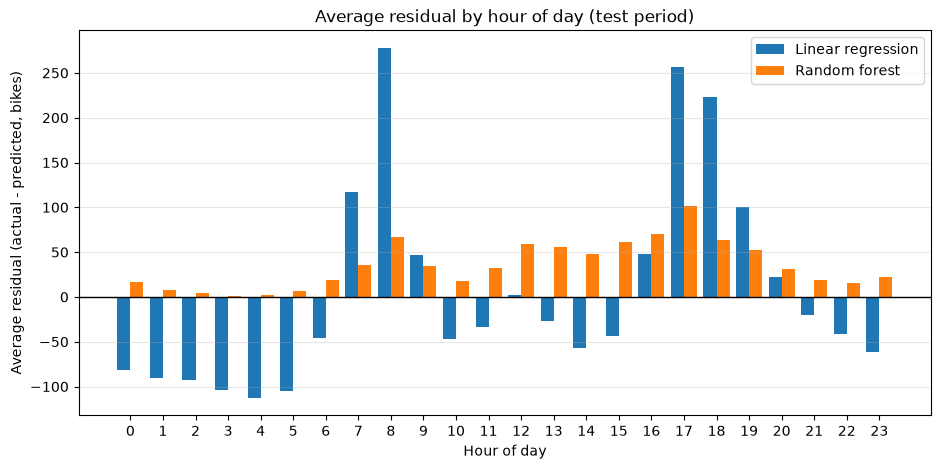

,y_true,linear,forest
hr,,,
3,14.8,118.6,13.6
8,489.4,211.6,422.8
17,617.0,360.4,515.3


In [3]:
preds['res_linear'] = preds['y_true'] - preds['linear']
preds['res_forest'] = preds['y_true'] - preds['forest']

by_hour = preds.groupby('hr')[['res_linear', 'res_forest']].mean()

x = np.arange(24)
w = 0.4
plt.figure(figsize=(11, 5))
plt.bar(x - w / 2, by_hour['res_linear'], width=w, label='Linear regression')
plt.bar(x + w / 2, by_hour['res_forest'], width=w, label='Random forest')
plt.axhline(0, color='black', linewidth=1)
plt.xticks(x)
plt.xlabel('Hour of day')
plt.ylabel('Average residual (actual - predicted, bikes)')
plt.title('Average residual by hour of day (test period)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig('../results/figures/residual_vs_hour.png', dpi=150, bbox_inches='tight')
plt.show()

# Average actual and predicted demand at three key hours
preds[preds['hr'].isin([3, 8, 17])].groupby('hr')[['y_true', 'linear', 'forest']].mean().round(1)

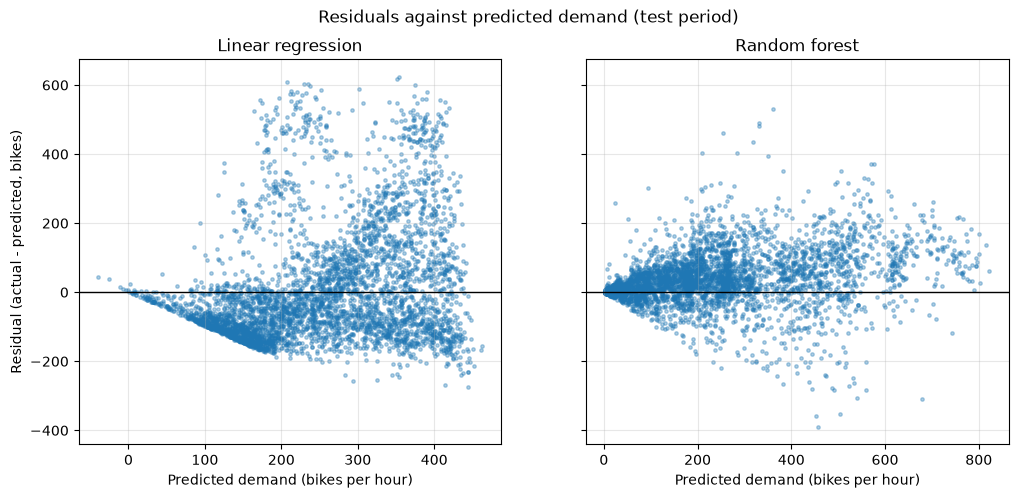

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, col, title in [(axes[0], 'linear', 'Linear regression'),
                       (axes[1], 'forest', 'Random forest')]:
    ax.scatter(preds[col], preds['y_true'] - preds[col], s=6, alpha=0.35)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Predicted demand (bikes per hour)')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Residual (actual - predicted, bikes)')
plt.suptitle('Residuals against predicted demand (test period)')
plt.savefig('../results/figures/residual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

**Residuals against hour.** The linear model under-predicts both rush hours badly. At 8 a.m. the real average demand in the test period is about 489 bikes but the linear model predicts about 212, so it is too low by about 278 bikes on average. At 5 p.m. the real value is about 617 and the prediction is about 360 (too low by about 257). At night it does the opposite: at 3 a.m. it predicts about 119 bikes when the real value is about 15, and 6 of its predictions are negative, which is impossible. This is what we expect from a model that can only draw one smooth wave over the day and cannot make two sharp peaks. For an operator, the 8 a.m. result means the linear model would plan for about 280 fewer bikes than people really rent, so stands would run empty exactly at the busiest time. The random forest follows the daily shape much better (its average residual is between about 1 and 102 bikes at every hour), but it still under-predicts the rush hours a little, most at 5 p.m. (about 102) and at 8 a.m. (about 67).

**Residuals against predicted demand.** If a model were right, the points would be spread evenly around zero. For the linear model they are not: the errors are large at almost every predicted level (typically 120 to 190 bikes for predictions above 100) and the sign changes with the prediction, which shows the straight-line model misses the shape of demand. For the random forest, the errors are small when predicted demand is low (typically about 26 bikes below 100) and grow as predicted demand grows (about 115 bikes between 400 and 600). Its average residual is positive in every group, so it tends to predict slightly too few bikes, mostly at high demand.

## 4.3 Errors in peak hours

Peak hours are the hours where real demand is above the 90th percentile of the test period. These are the hours in which a fleet operator needs the forecast the most.

In [5]:
threshold = preds['y_true'].quantile(0.90)
peak = preds[preds['y_true'] > threshold]
print('Peak threshold: %.1f bikes per hour, peak hours: %d of %d' % (threshold, len(peak), len(preds)))

rows = []
for name in model_names:
    rows.append({
        'model': name,
        'overall RMSE': np.sqrt(mean_squared_error(preds['y_true'], preds[name])),
        'peak RMSE': np.sqrt(mean_squared_error(peak['y_true'], peak[name])),
        'average error at peaks (actual - predicted)': (peak['y_true'] - peak[name]).mean(),
    })

peak_table = pd.DataFrame(rows)
peak_table.round(1)

Peak threshold: 577.5 bikes per hour, peak hours: 438 of 4376


,model,overall RMSE,peak RMSE,average error at peaks (actual - predicted)
0,baseline,191.3,443.4,430.2
1,linear,165.7,401.6,385.5
2,ridge,165.7,401.6,385.5
3,lasso,165.7,401.6,385.5
4,forest,83.7,161.8,137.7


**What this shows.** Peak hours are the hardest hours for every model. The peak threshold is about 578 bikes per hour (438 hours). For the linear models the RMSE in peak hours is about 402, which is more than twice their overall RMSE of 166, and they are too low by about 386 bikes on average. For the random forest the peak RMSE is about 162 against an overall RMSE of 84, and it is too low by about 138 bikes on average. So even the best model misses the busiest hours the most, and an operator should plan a safety margin on top of the forecast at rush hour.

## 4.4 RMSE or R²: which one to report to the operator

I would report **RMSE** (with MAE next to it) to the operator. RMSE is in bikes, so it directly says how far off a forecast can be: about 84 bikes per hour for the random forest. A truck planner can use that number. R² has no unit and depends on how spread out the demand in the test period is (the standard deviation of hourly demand here is about 220 bikes), so the same model can show a different R² in a quieter period or another city, and nobody can turn 0.855 into a number of bikes to move. RMSE also punishes big misses more than small ones, which fits fleet planning, because being 300 bikes short at a rush hour is much worse than being 30 bikes short several times. R² is still useful as a quick check of how much better a model is than always predicting the average.

## 4.5 Ridge coefficients

We refit the final Ridge model on the training period with the alpha chosen in `03-models.ipynb` (read from `results/best_params.csv`). The numeric features were standardised, so their coefficients mean bikes per hour for a change of one standard deviation. Season, weather and weekday columns are 0 or 1, so their coefficients are bikes per hour compared with the other categories.

Ridge alpha from best_params.csv: 0.001
Test RMSE of the refitted Ridge: 165.73


,coefficient
hour__hr_cos,-85.8
hour__hr_sin,-83.4
cat__weathersit_3,-33.4
cat__season_1,-26.6
cat__weathersit_4,-23.6
month__mnth_cos,-14.9
bin__holiday,-12.4
cat__season_3,-10.4
month__mnth_sin,-9.7
num__hum,-6.9


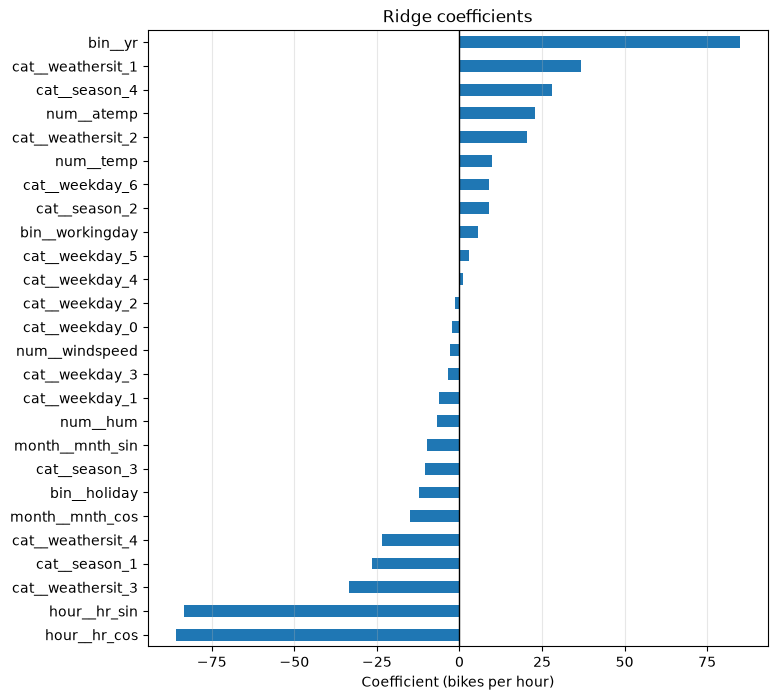

In [6]:
best = pd.read_csv('../results/best_params.csv', dtype=str)
ridge_alpha = float(best[(best['model'] == 'ridge') & (best['param'] == 'alpha')]['value'].iloc[0])
print('Ridge alpha from best_params.csv:', ridge_alpha)

df = load_hour_data()
train, test = chronological_split(df)
X_train, y_train = get_xy(train)
X_test, y_test = get_xy(test)

ridge_final = Pipeline([
    ('prep', build_preprocessor()),
    ('model', Ridge(alpha=ridge_alpha)),
])
ridge_final.fit(X_train, y_train)

# Check: this should match the Ridge RMSE in the metrics table
check = np.sqrt(mean_squared_error(y_test, ridge_final.predict(X_test)))
print('Test RMSE of the refitted Ridge: %.2f' % check)

names = ridge_final.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(ridge_final.named_steps['model'].coef_, index=names).sort_values()
display(coefs.round(1).to_frame('coefficient'))

plt.figure(figsize=(8, 8))
coefs.plot(kind='barh')
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Coefficient (bikes per hour)')
plt.title('Ridge coefficients')
plt.grid(axis='x', alpha=0.3)
plt.savefig('../results/figures/ridge_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**Three coefficients in plain words**

**1. Weather (`weathersit`).** Compared with clear weather (coefficient about +37), light rain or snow (level 3, about -33) lowers demand by about 70 bikes per hour, and mist (level 2, about +20) lowers it by about 16, when the hour, the day and the temperature are the same. For the operator: on a rainy day plan for far fewer rentals at the same hour, so fewer bikes have to be moved to busy stations. (The heavy rain level 4 has only 3 rows, all in the training period, so its coefficient is not reliable and we do not interpret it.)

**2. Year (`yr`).** The coefficient is about +85. For the same hour, weather and type of day, 2012 had about 85 more rentals per hour than 2011. This is the strong growth of the system, and it means last year's numbers are too low for this year. It is also a warning: the model only knows the values 0 (2011) and 1 (2012), so it cannot predict a new year like 2013 without new data.

**3. Temperature (`temp` and `atemp`).** These two columns are almost the same measurement (correlation 0.99), so they should be read together. Their coefficients are about +10 and +23, each for a change of one standard deviation (about 8 degrees Celsius). So when it is about 8 degrees warmer, the model expects about 33 more rentals per hour. For the operator: warm days need more bikes in the field and cold days need fewer.

**Sign check: does bad weather reduce demand in our model?** Yes. The coefficients go down from clear (+37) to mist (+20) to light rain or snow (-33), which is the order we expected, and it matches the EDA chart (average demand about 205, 175 and 112 for weather levels 1, 2 and 3). Humidity (about -7) and wind speed (about -3) are also negative and temperature is positive, as expected. The hour columns (`hr_sin` and `hr_cos`) have the largest coefficients (about -83 and -86), but they only make sense together as one daily wave, so we do not read them one by one.

## 4.6 Limitations

- The data is one city-wide hourly total. It has no station-level information, so it cannot say where to move bikes, only how many bikes will be rented overall.
- The models use the real weather of that hour. In real use the operator would only have a weather forecast, which is less accurate, so real errors would be larger.
- The year column cannot extrapolate to a new year, and the test period only covers July to December 2012.
- 165 hours are missing from the data (0.94%), mostly quiet night hours and four long gaps. We kept them as missing and did not fill them.
- The linear models cannot make two daily peaks, so they miss the rush hours. All models under-predict the busiest hours.

## 4.7 Check: should the final pipeline use one-hot hour?

In `02-preprocessing.ipynb`, one-hot hour was the best hour encoding for linear regression. The final pipeline in `src/preprocessing.py` uses cyclic hour. Here we test both options in the full pipeline, with plain linear regression and the random forest (200 trees, `random_state=42`, same settings as the tuned model).

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from preprocessing import cyclic_transformer

def make_preprocessor(hour_mode):
    if hour_mode == 'cyclic':
        hour_step = ('hour', cyclic_transformer(24), ['hr'])
    else:
        hour_step = ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr'])
    return ColumnTransformer([
        hour_step,
        ('month', cyclic_transformer(12), ['mnth']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['season', 'weathersit', 'weekday']),
        ('num', StandardScaler(), ['temp', 'atemp', 'hum', 'windspeed']),
        ('bin', 'passthrough', ['yr', 'holiday', 'workingday']),
    ])

rows = []
for mode in ['cyclic', 'one-hot']:
    for model_name, model in [
        ('linear', LinearRegression()),
        ('forest', RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    ]:
        pipe = Pipeline([('prep', make_preprocessor(mode)), ('model', model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        rows.append({
            'hour encoding': mode,
            'model': model_name,
            'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
            'MAE': mean_absolute_error(y_test, pred),
            'R2': r2_score(y_test, pred),
        })

pd.DataFrame(rows).round(3)

,hour encoding,model,RMSE,MAE,R2
0,cyclic,linear,165.733,123.920,0.431
1,cyclic,forest,83.531,56.308,0.855
2,one-hot,linear,135.640,101.054,0.619
3,one-hot,forest,92.739,64.224,0.822


**Decision.** One-hot hour helps the linear model a lot (RMSE from about 166 to about 136, R² from about 0.43 to about 0.62), because it lets the model make two daily peaks. But it makes the random forest slightly worse (RMSE from about 84 to about 93). A likely reason is that a tree can group neighbouring hours with one split when it has the sine and cosine pair, while 24 separate yes/no columns make each split look at only one hour. The random forest is the best model by a wide margin with either encoding, and it is the model we would give the operator, so we keep the cyclic hour encoding in the final pipeline. If only linear models were used, one-hot hour would be the better choice.

## Summary

- Best model: random forest, RMSE about 84 bikes per hour, MAE about 56, R² about 0.855 on July to December 2012.
- Linear regression, Ridge and Lasso are almost identical (RMSE about 166, R² about 0.43); regularisation did not help.
- The linear models cannot represent the two daily rush hours and under-predict them by hundreds of bikes.
- All models make their biggest errors in the busiest hours.
- Coefficients behave as expected: bad weather lowers demand, warm weather raises it, and 2012 had much more demand than 2011.
- Headline metric for the operator: RMSE, because it is in bikes.